In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from torch.utils.data import DataLoader, Dataset
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

from collections import Counter
import random

# Tokenización e Indexación

In [2]:
file_name = 'data/IMDB Dataset.csv'
df = pd.read_csv(file_name)
print(df.loc[0,'review'])
df.head()

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


train data shape: (37500,)
test data shape: (12500,)


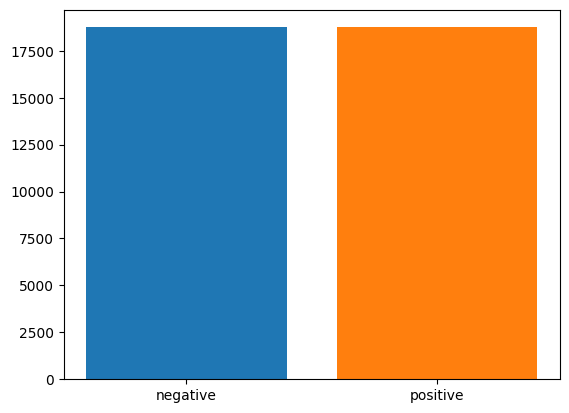

In [3]:
X,y = df['review'].values,df['sentiment'].values
x_train,x_test,y_train,y_test = train_test_split(X,y,stratify=y)
print(f'train data shape: {x_train.shape}')
print(f'test data shape: {x_test.shape}')

dd = pd.Series(y_train).value_counts()
plt.bar(np.array(['negative','positive']),dd.values,color=['tab:blue','tab:orange'])
plt.show()

## Cómo procesar texto
1. ¿Cómo considero el texto? ¿Un vector de letras? ¿Las letras son numeros?
2. ¿Cómo se podría procesar una oración de distintos largos?

In [4]:

nltk.download("stopwords")
# stop_words = set(stopwords.words("english"))

def preprocess_string(s):
    # Remove all non-word characters (everything except numbers and letters)
    s = re.sub(r"[^\w\s]", '', s)
    # Replace all runs of whitespaces with no space
    s = re.sub(r"\s+", '', s)
    # replace digits with no space
    s = re.sub(r"\d", '', s)
    return s


def tokenize(x_train,y_train,x_val,y_val):
    word_list = []

    stop_words = set(stopwords.words('english'))
    for sent in x_train:
        for word in sent.lower().split():
            word = preprocess_string(word)
            if word not in stop_words and word != '':
                word_list.append(word)

    corpus = Counter(word_list)
    # sorting on the basis of most common words
    corpus_ = sorted(corpus,key=corpus.get,reverse=True)[:1000]
    # creating a dict
    onehot_dict = {w:i+1 for i,w in enumerate(corpus_)}

    # tokenize
    final_list_train,final_list_test = [],[]
    for sent in x_train:
            final_list_train.append([onehot_dict[preprocess_string(word)] for word in sent.lower().split()
                                     if preprocess_string(word) in onehot_dict.keys()])
    for sent in x_val:
            final_list_test.append([onehot_dict[preprocess_string(word)] for word in sent.lower().split()
                                    if preprocess_string(word) in onehot_dict.keys()])

    encoded_train = [1 if label =='positive' else 0 for label in y_train]
    encoded_test = [1 if label =='positive' else 0 for label in y_val]

    X_train = final_list_train
    Y_train = np.array(encoded_train)
    X_test = final_list_test
    Y_test = np.array(encoded_test)
    return X_train,Y_train,X_test,Y_test,onehot_dict


x_train,y_train,x_test,y_test,vocab = tokenize(x_train,y_train,x_test,y_test)

[nltk_data] Downloading package stopwords to /home/luis/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


<Axes: >

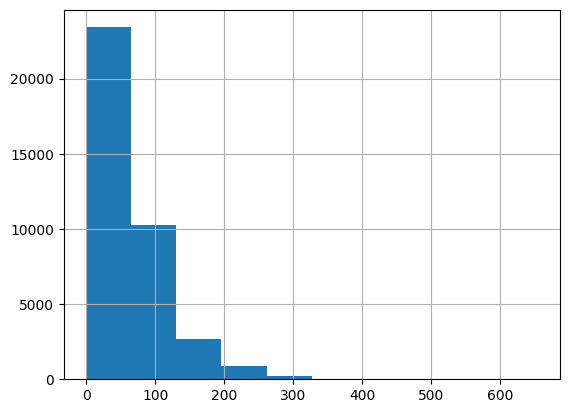

In [5]:
rev_len = [len(i) for i in x_train]
pd.Series(rev_len).hist()

In [6]:
def padding_(sentences, seq_len):
    features = np.zeros((len(sentences), seq_len),dtype=int)
    for ii, review in enumerate(sentences):
        if len(review) != 0:
            features[ii, -len(review):] = np.array(review)[:seq_len]
    return features

max_length = 500
x_train_pad = padding_(x_train,max_length)
x_test_pad = padding_(x_test,max_length)

# IMDB Dataset of 50K Movie Reviews
Es un conjunto de datos de IMDb que contiene 50.000 reseñas de películas, destinado al procesamiento de lenguaje natural.
Se trata de un conjunto de datos para la clasificación binaria de sentimientos. La idea es poder entrenar un modelo para que pueda comprender el uso del lenguaje para definir si hay una resena positiva o negativa. Este contiene 25.000 reseñas de películas para entrenamiento  y otras 25 000 para la evaluación.

In [7]:
class TextDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


batch_size = 64
vocab_size = len(vocab) + 1  # Index 0 is reserved for padding

train_dataset = TextDataset(x_train_pad, y_train)
test_dataset = TextDataset(x_test_pad, y_test)


# Construir una red neuronal
Vamos a utilizar el modulo LSTM

In [8]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, num_layers=1, dropout=0.1):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        h0 = torch.zeros(self.num_layers * 2, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers * 2, x.size(0), self.hidden_dim).to(x.device)

        lstm_out, _ = self.lstm(embedded, (h0, c0))

        output = self.dropout(lstm_out[:, -1, :])
        output = self.fc(output)

        return output


# Como interpretar embeddings
1. Utilice `plot_embeddings` para graficar embeddings de dos palabras semánticamente opuestas.
2. Defina una función calculate distance que calcule la euclidiana entre dos embeddings.
3. Evalúa la distancia entre dos palabras semánticamente opuestas y dos palabras semánticamente cercanas.


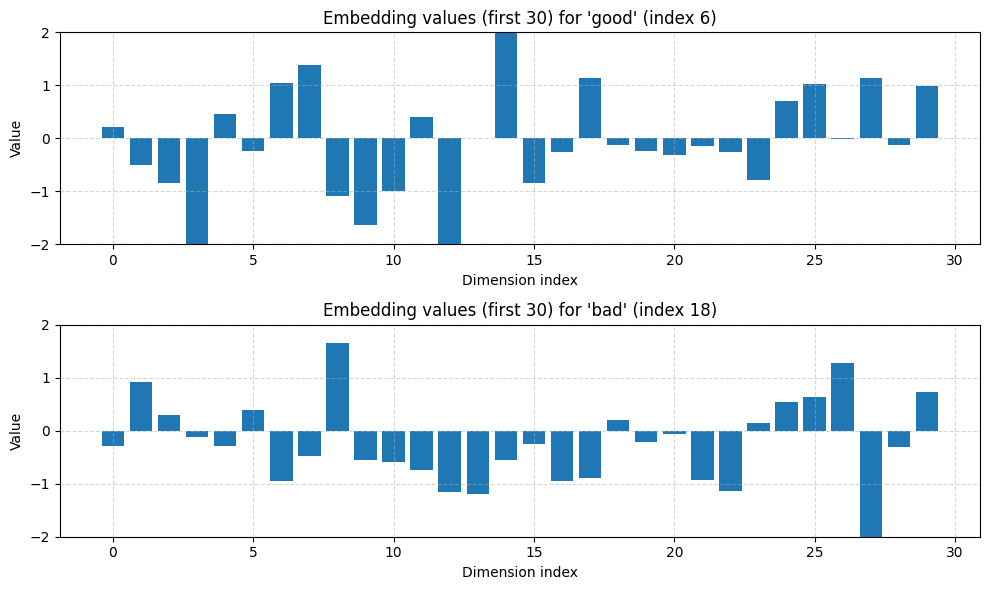

Distancia euclidiana inicial (opuestas: 'good' vs 'bad'): 16.0033
Distancia euclidiana inicial (cercanas: 'good' vs 'great'): 16.3038


In [20]:
def plot_embeddings(embedding_bank: torch.Tensor, words_indices: list[int], scale=(-2, 2)):
    if isinstance(embedding_bank, nn.Embedding):
        weights = embedding_bank.weight.detach().cpu().numpy()
    elif isinstance(embedding_bank, torch.Tensor):
        weights = embedding_bank.detach().cpu().numpy()
    else:
        weights = np.array(embedding_bank)

    n_words = len(words_indices)
    fig, axes = plt.subplots(n_words, 1, figsize=(10, 3 * n_words), squeeze=False)

    inv_vocab = {v: k for k, v in vocab.items()} if 'vocab' in globals() else {}

    for i, idx in enumerate(words_indices):
        ax = axes[i, 0]
        vals = weights[idx][:30]
        word_label = inv_vocab.get(idx, f"Token {idx}")
        ax.bar(range(len(vals)), vals, color='tab:blue')
        if scale is not None:
            ax.set_ylim(scale)
        ax.set_title(f"Embedding values (first 30) for '{word_label}' (index {idx})")
        ax.set_xlabel("Dimension index")
        ax.set_ylabel("Value")
        ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()


def calculate_distance(emb1, emb2):
    """
    Calculates the euclidean distance between two embeddings.
    """

    emb1 = emb1.detach().cpu().numpy()

    emb2 = emb2.detach().cpu().numpy()
    # Code here.


# Ejemplo: Evaluar embeddings antes de entrenar
sample_tokens = [vocab.get('good'), vocab.get('bad')]
valid_tokens = [idx for idx in sample_tokens if idx is not None]
emb_size = 128
h_dim = 128
lstm_model = LSTMClassifier(vocab_size, embedding_dim=128, hidden_dim=128, num_classes=2, num_layers=1, dropout=0.1)
temp_embedding = lstm_model.embedding
if len(valid_tokens) >= 2:
    plot_embeddings(temp_embedding, valid_tokens, scale=(-2, 2))
    dist_init_opp = calculate_distance(temp_embedding.weight[valid_tokens[0]], temp_embedding.weight[valid_tokens[1]])
    print(f"Distancia euclidiana inicial (opuestas: 'good' vs 'bad'): {dist_init_opp:.4f}")

if 'good' in vocab and 'great' in vocab:
    dist_init_sim = calculate_distance(temp_embedding.weight[vocab['good']], temp_embedding.weight[vocab['great']])
    print(f"Distancia euclidiana inicial (cercanas: 'good' vs 'great'): {dist_init_sim:.4f}")


In [11]:
def train_classification(model: nn.Module, loader: DataLoader, optimizer, train_loss: list, train_acc: list, device='cpu'):
    """
    Runs one pass over the loader (training if an optimizer is given).
    """
    model.train(True)
    total_ce = 0.
    n_batches = 0
    correct, n_positive = 0, 0
    loss_fn = nn.CrossEntropyLoss()

    for data, targets in loader:
        data = data.to(device)
        targets = targets.to(device)
        out = model(data)
        if isinstance(out, tuple):
            pred = out[1]
        else:
            pred = out
        ce_loss = loss_fn(pred, targets)

        optimizer.zero_grad()
        ce_loss.backward()
        optimizer.step()

        total_ce += ce_loss.item()
        n_batches += 1

        correct += (pred.argmax(dim=1) == targets).sum().item()
        n_positive += len(targets)

    epoch_loss = total_ce / max(n_batches, 1)
    epoch_acc = correct / max(n_positive, 1)
    train_loss.append(epoch_loss)
    train_acc.append(epoch_acc)
    return train_loss, train_acc


def test_classification(model: nn.Module, loader: DataLoader, test_loss: list, test_acc: list, device='cpu'):
    """
    Runs one pass over the test loader in evaluation mode and records loss and accuracy.
    """
    model.eval()
    total_ce = 0.
    n_batches = 0
    correct, n_positive = 0, 0
    loss_fn = nn.CrossEntropyLoss()

    with torch.no_grad():
        for data, targets in loader:
            data = data.to(device)
            targets = targets.to(device)
            out = model(data)
            if isinstance(out, tuple):
                pred = out[1]
            else:
                pred = out
            ce_loss = loss_fn(pred, targets)

            total_ce += ce_loss.item()
            n_batches += 1

            correct += (pred.argmax(dim=1) == targets).sum().item()
            n_positive += len(targets)

    epoch_loss = total_ce / max(n_batches, 1)
    epoch_acc = correct / max(n_positive, 1)
    test_loss.append(epoch_loss)
    test_acc.append(epoch_acc)
    return test_loss, test_acc


In [12]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

n_classes = 2
epochs = 20
lr = 0.001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\n" + "="*50)
print("Evaluating Architectures:")

print("="*50)

print(f"\n--- Training Single-Layer LSTM Network ({epochs} epochs) ---")

lstm_model.to(device)
optimizer = optim.Adam(lstm_model.parameters(), lr=lr)

train_losses = []
train_accs = []
test_losses = []
test_accs = []

for epoch in tqdm(range(epochs), desc=f"Training {lstm_model.__class__.__name__}"):
    train_classification(lstm_model, train_loader, optimizer, train_losses, train_accs, device=device)
    test_classification(lstm_model, test_loader, test_losses, test_accs, device=device)
    print(f"Epoch {epoch + 1:02d}/{epochs:02d} | "
          f"Train Loss: {train_losses[-1]:.4f} - Train Acc: {train_accs[-1]*100:.2f}% | "
          f"Test Loss: {test_losses[-1]:.4f} - Test Acc: {test_accs[-1]*100:.2f}%")



Evaluating Architectures:

--- Training Single-Layer LSTM Network (20 epochs) ---


Training LSTMClassifier:   5%|▌         | 1/20 [00:12<03:57, 12.51s/it]

Epoch 01/20 | Train Loss: 0.5026 - Train Acc: 74.93% | Test Loss: 0.4470 - Test Acc: 80.92%


Training LSTMClassifier:  10%|█         | 2/20 [00:24<03:42, 12.34s/it]

Epoch 02/20 | Train Loss: 0.3835 - Train Acc: 83.29% | Test Loss: 0.3775 - Test Acc: 83.94%


Training LSTMClassifier:  15%|█▌        | 3/20 [00:37<03:29, 12.31s/it]

... (31 outputs left out)

Training LSTMClassifier:  95%|█████████▌| 19/20 [03:56<00:12, 12.53s/it]

Epoch 19/20 | Train Loss: 0.0249 - Train Acc: 99.25% | Test Loss: 0.8871 - Test Acc: 84.37%


Training LSTMClassifier: 100%|██████████| 20/20 [04:08<00:00, 12.43s/it]

Epoch 20/20 | Train Loss: 0.0226 - Train Acc: 99.39% | Test Loss: 0.9088 - Test Acc: 83.38%


Adam:  train 0.9939   test: 0.8338


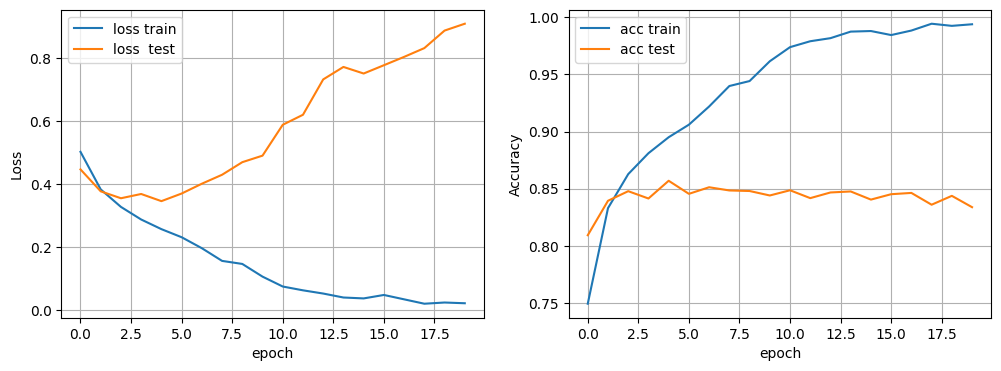

In [14]:
results =  {'train_losses': train_losses, 'test_losses': test_losses, 'train_accuracy': train_accs, 'test_accuracy': test_accs}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results["train_losses"], "C0", label="loss train")
axes[0].plot(results["test_losses"], "C1", label="loss  test")

axes[1].plot(results["train_accuracy"], "C0", label="acc train")
axes[1].plot(results["test_accuracy"], "C1", label="acc test")
print(f"Adam:  train {results['train_accuracy'][-1]:.4f}   test: {results['test_accuracy'][-1]:.4f}")

axes[0].set_ylabel('Loss')
axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.grid()
    ax.legend()
    ax.set_xlabel('epoch')
plt.show()

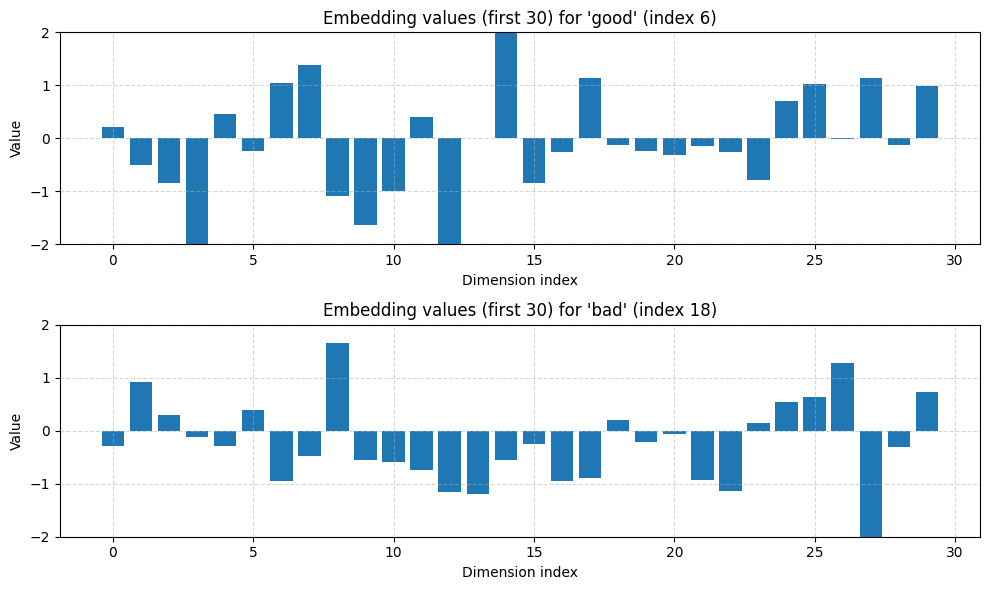

Distancia euclidiana entrenada (opuestas: 'good' vs 'bad'): 16.0033
Distancia euclidiana entrenada (cercanas: 'good' vs 'great'): 16.3038


In [15]:
# 1. Re-evaluar los embeddings entrenados
if len(valid_tokens) >= 2:
    plot_embeddings(lstm_model.embedding, valid_tokens, scale=(-2, 2))
    dist_trained_opp = calculate_distance(lstm_model.embedding.weight[valid_tokens[0]], lstm_model.embedding.weight[valid_tokens[1]])
    print(f"Distancia euclidiana entrenada (opuestas: 'good' vs 'bad'): {dist_trained_opp:.4f}")

if 'good' in vocab and 'great' in vocab:
    dist_trained_sim = calculate_distance(lstm_model.embedding.weight[vocab['good']], lstm_model.embedding.weight[vocab['great']])
    print(f"Distancia euclidiana entrenada (cercanas: 'good' vs 'great'): {dist_trained_sim:.4f}")




# Evaluando embeddings.
1. Vuelva a evaluar los embeddings considerando sus gráficos y sus distancias.
2. ¿Nota algún cambio?
3. Describe el funcionamiento de esta arquitectura:


![image_multilayer_LSTM](https://imgs.search.brave.com/KHZ9IPShbe4rikcVJyz2-vx3pOuM69QS3bre1l1Nflw/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly9uaW1h/c2FyYW5nLmNvbS9i/bG9nLzIwMjQtMDYt/MTUtbHN0bS1mcm9t/LXNjcmF0Y2gvaW1h/Z2VzL211bHRpbGF5/ZXJfbHN0bS5wbmc)


4. Has un segundo entrenamiento con mas capas de LSTM con multiples capas LSTM.


In [ ]:



# 4. Segundo entrenamiento con más capas de LSTM (MultiLayerLSTMClassifier)
print(f"\n--- Training Multi-Layer LSTM Network ({epochs} epochs) ---")
multi_lstm_model = LSTMClassifier(vocab_size, embedding_dim=128, hidden_dim=128, num_classes=2, num_layers=3, dropout=0.1)
multi_lstm_model.to(device)
multi_optimizer = optim.Adam(multi_lstm_model.parameters(), lr=lr)

multi_train_losses = []
multi_train_accs = []
multi_test_losses = []
multi_test_accs = []

for epoch in tqdm(range(epochs), desc=f"Training {multi_lstm_model.__class__.__name__}"):
    train_classification(multi_lstm_model, train_loader, multi_optimizer, multi_train_losses, multi_train_accs, device=device)
    test_classification(multi_lstm_model, test_loader, multi_test_losses, multi_test_accs, device=device)
    print(f"Epoch {epoch + 1:02d}/{epochs:02d} | "
          f"Train Loss: {multi_train_losses[-1]:.4f} - Train Acc: {multi_train_accs[-1]*100:.2f}% | "
          f"Test Loss: {multi_test_losses[-1]:.4f} - Test Acc: {multi_test_accs[-1]*100:.2f}%")
